# Clasificacion de rostros

Ejecuta las celdas en orden. Despu?s del entrenamiento, puedes volver a ejecutar la celda de gr?ficas para consultar los resultados.


## Importaciones y carga del conjunto de imagenes


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import json

from tensorflow.keras import layers, models

# Las carpetas de cada persona están junto a este archivo.
PROJECT_DIR = os.getcwd()
DATA_DIR = PROJECT_DIR

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(
        f"No se encontró la carpeta de imágenes:\n{DATA_DIR}"
    )

# Configuración de las imágenes
IMG_SIZE = 128
BATCH_SIZE = 32

# Dataset de entrenamiento (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

# Dataset de validación (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

# Obtener los nombres de las personas
class_names = train_ds.class_names

# Cantidad de personas que reconocerá el modelo
num_classes = len(class_names)

print("Personas detectadas:", class_names)
print("Cantidad de clases:", num_classes)



Found 973 files belonging to 9 classes.
Using 779 files for training.
Found 973 files belonging to 9 classes.
Using 194 files for validation.
Personas detectadas: ['Brad Pitt', 'Emilio', 'Fernando', 'Iran', 'Robert Downey Jr', 'Santiago', 'Scarlett Johansson', 'Tom Cruise', 'Will Smith']
Cantidad de clases: 9


## Vista previa de imagenes


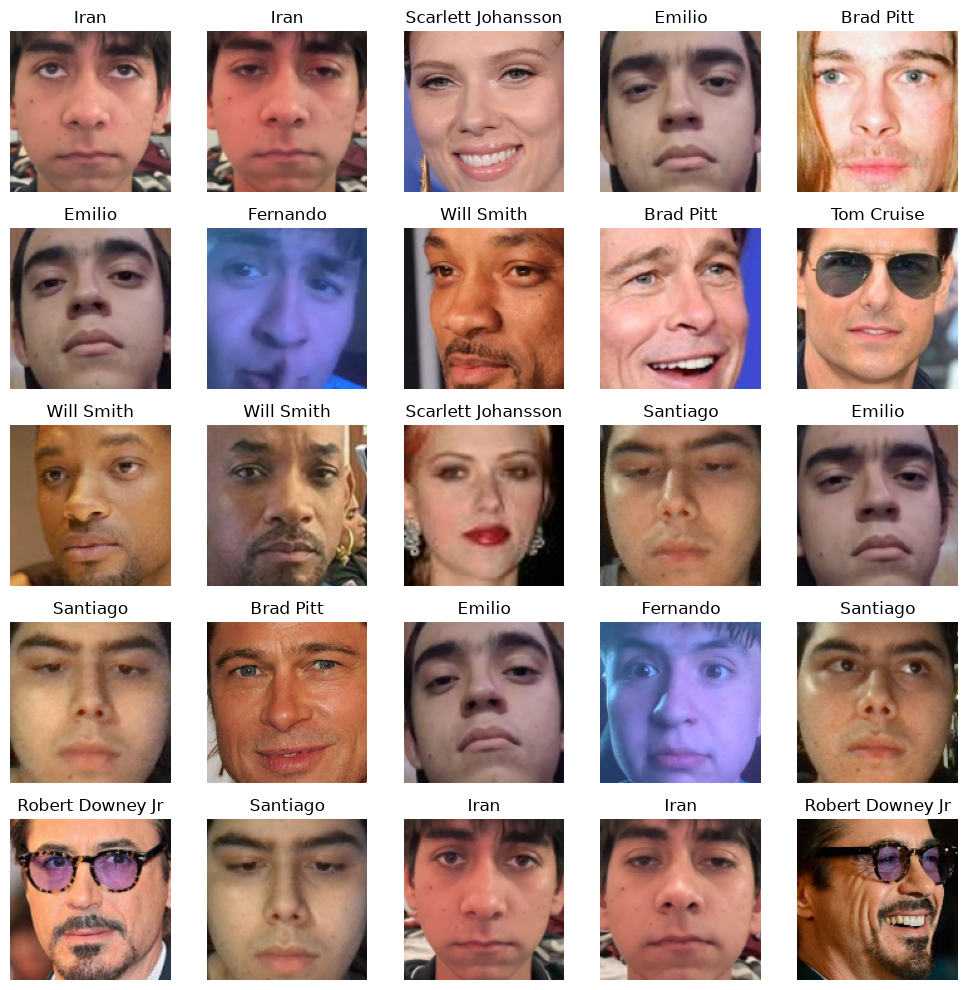

In [7]:
plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        etiqueta = np.argmax(labels[i].numpy())

        plt.title(class_names[etiqueta])
        plt.axis("off")

plt.tight_layout()
plt.show()



## Construccion y configuracion del modelo


In [3]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.Rescaling(1. / 127.5, offset=-1),
    base_model,
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

model.summary()

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [

    # Detiene el entrenamiento si deja de mejorar
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),

    # Guarda el mejor modelo
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(PROJECT_DIR, "mejor_modelo.keras"),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True
    )
]



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 2, 2, 1280)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5120)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5120)           │        20,480 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5120)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       655,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,935,113 (11.20 MB)

 Trainable params: 666,889 (2.54 MB)

 Non-trainable params: 2,268,224 (8.65 MB)

## Entrenamiento


In [4]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=40,
    callbacks=callbacks
)



Epoch 1/40


C:\Users\guaya\AppData\Roaming\Python\Python314\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


25/25 ━━━━━━━━━━━━━━━━━━━━ 12s 362ms/step - accuracy: 0.6637 - loss: 1.3698 - val_accuracy: 0.7165 - val_loss: 1.3683
Epoch 2/40
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 229ms/step - accuracy: 0.8716 - loss: 0.4024 - val_accuracy: 0.8351 - val_loss: 0.6642
Epoch 3/40
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 258ms/step - accuracy: 0.8960 - loss: 0.3353 - val_accuracy: 0.8660 - val_loss: 0.6147
Epoch 4/40
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 209ms/step - accuracy: 0.9063 - loss: 0.2952 - val_accuracy: 0.8711 - val_loss: 0.5342
Epoch 5/40
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 147ms/step - accuracy: 0.9191 - loss: 0.2682 - val_accuracy: 0.8608 - val_loss: 0.5521
Epoch 6/40
25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 124ms/step - accuracy: 0.9320 - loss: 0.2080 - val_accuracy: 0.8711 - val_loss: 0.4954
Epoch 7/40
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 226ms/step - accuracy: 0.9397 - loss: 0.1800 - val_accuracy: 0.8814 - val_loss: 0.5033
Epoch 8/40
25/25 ━━━━━━━━━━━━━━━━━━━━ 7s 269ms/step - accuracy: 0.9499 - loss: 0.1969 - val_accuracy: 0.8918 - val

## Graficas de entrenamiento


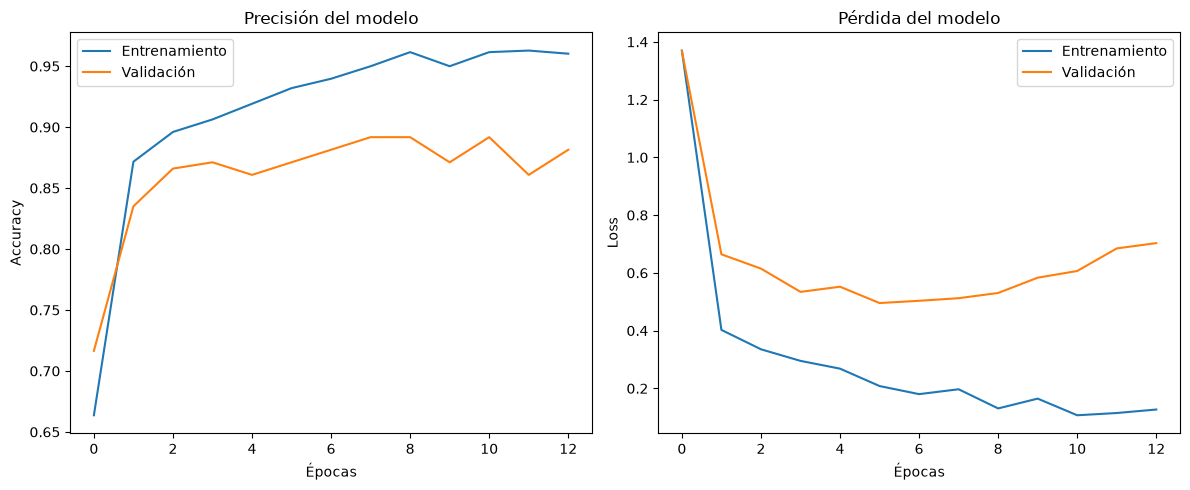

In [5]:
plt.figure(figsize=(12,5))

# Gráfica de precisión
plt.subplot(1,2,1)

plt.plot(history.history["accuracy"], label="Entrenamiento")
plt.plot(history.history["val_accuracy"], label="Validación")

plt.title("Precisión del modelo")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend()

# Gráfica de pérdida
plt.subplot(1,2,2)

plt.plot(history.history["loss"], label="Entrenamiento")
plt.plot(history.history["val_loss"], label="Validación")

plt.title("Pérdida del modelo")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()



## Guardado de etiquetas


In [6]:
with open(os.path.join(PROJECT_DIR, "clases.json"), "w", encoding="utf-8") as archivo:
    json.dump(class_names, archivo, ensure_ascii=False)

print("Modelo y etiquetas guardados correctamente.")

Modelo y etiquetas guardados correctamente.
